# 03 Simulator check (pilot: January and June 2025)

**Everything in this notebook is SIMULATED.** The data comes from `src/simulation` running on the real (old) Corridor B timetable. No real delay data was used or exists in this project.

The calibration targets below are **plausible assumptions, not verified facts**: most arrivals within 10 minutes, a heavy tail, worse in fog months and for long-distance trains, delay growing along a route unless slack absorbs it, and visible cascades. The parameters were tuned by hand after a first check (see section 12 of the design document); they were not fitted to real Indian Railways data.

In [1]:
import os, sys, json
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, ".")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.simulation import causes as C
from src.simulation.config import load_config
from src.simulation.network import load_specs
from src.simulation.run import simulate, to_day

ROOT = Path("data/processed/sim_pilot")
MONTHS = {"jan": "January (winter, fog season)", "jun": "June (summer)"}
COL = {"jan": "#1f6f9f", "jun": "#d98c1f"}            # blue / orange: a colour-blind-safe pair
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "font.size": 9})
def sim_title(ax, t):
    ax.set_title(t + "   [SIMULATED]", loc="left", fontweight="bold")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)

net, specs, link_stats, cfg = load_specs()
obs = pd.concat([pd.read_parquet(ROOT / m / "observations").assign(run=m) for m in MONTHS], ignore_index=True)
attr = pd.concat([pd.read_parquet(ROOT / m / "delay_attribution").assign(run=m) for m in MONTHS], ignore_index=True)
events = pd.concat([pd.read_parquet(ROOT / m / "events.parquet").assign(run=m) for m in MONTHS], ignore_index=True)
weather = pd.concat([pd.read_parquet(ROOT / m / "weather.parquet").assign(run=m) for m in MONTHS], ignore_index=True)
queues = pd.concat([pd.read_parquet(ROOT / m / "queues.parquet").assign(run=m) for m in MONTHS], ignore_index=True)
timing = json.load(open(ROOT / "timing.json"))
obs["train"] = obs.train.astype(str); obs["station"] = obs.station.astype(str)
ttype = {t: s.type for t, s in specs.items()}
obs["type"] = obs.train.map(ttype)
obs["hour"] = ((obs.scheduled_arrival % 1440) // 60).astype(int)
obs["month_label"] = obs.run.map({"jan": "January", "jun": "June"})
print(len(obs), "observation rows;", len(attr), "attribution rows;", len(events), "events;", len(queues), "waits logged")
print("all tables flagged simulated:", bool(obs.is_simulated.all() and attr.is_simulated.all() and events.is_simulated.all()))

948550 observation rows; 2849901 attribution rows; 16726 events; 130296 waits logged
all tables flagged simulated: True


## 1. Calibration summary (targets are assumptions)

In [2]:
def summ(g):
    d = g.arrival_delay.dropna()
    return pd.Series({"rows": len(d), "mean": d.mean(), "median": d.median(), "p90": d.quantile(.9), "p99": d.quantile(.99),
                      "share <=5 min": (d <= 5).mean(), "share <=10 min": (d <= 10).mean(), "share >60 min": (d > 60).mean()})
cal = obs.groupby("run").apply(summ, include_groups=False).round(3)
print(cal)
tot = summ(obs).round(3); print("\nboth months:", tot.to_dict())
print("\nTarget (assumption): 70-85% within 10 min overall; p99 >= 90 min; winter worse than summer")

         rows    mean  median     p90      p99  share <=5 min  share <=10 min  share >60 min
run                                                                                         
jan  480035.0  21.046   4.818  63.078  168.537          0.503           0.580          0.109
jun  464550.0   8.281   0.000  25.209  102.617          0.712           0.778          0.026

both months: {'rows': 944585.0, 'mean': 14.768, 'median': 0.34, 'p90': 45.69, 'p99': 148.722, 'share <=5 min': 0.606, 'share <=10 min': 0.677, 'share >60 min': 0.068}

Target (assumption): 70-85% within 10 min overall; p99 >= 90 min; winter worse than summer


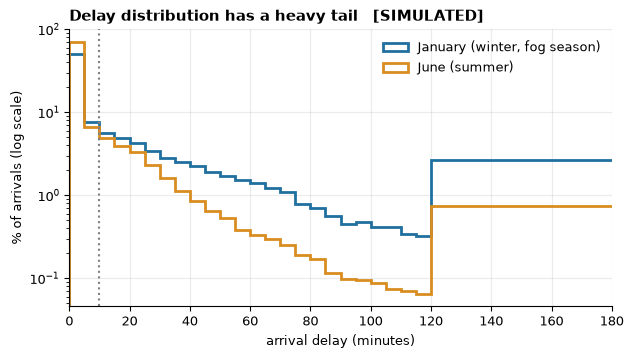

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.r_[np.arange(0, 120, 5), 120, 600]
for m in MONTHS:
    d = obs[obs.run == m].arrival_delay.dropna().clip(lower=0, upper=599)
    ax.hist(d, bins=bins, weights=np.full(len(d), 100 / len(d)), histtype="step", lw=2, color=COL[m], label=MONTHS[m])
ax.set_yscale("log"); ax.set_xlim(0, 180); ax.set_xlabel("arrival delay (minutes)"); ax.set_ylabel("% of arrivals (log scale)")
ax.axvline(10, color="grey", ls=":"); ax.legend(frameon=False); sim_title(ax, "Delay distribution has a heavy tail"); plt.show()

## 2. Delay by month and weather, hour, train type, distance and station

In [4]:
wx = weather.assign(date=pd.to_datetime(weather.date))[["run", "date", "state"]]
o = obs.merge(wx, on=["run", "date"], how="left")
t = o.groupby(["run", "state"], observed=True).arrival_delay.agg(["count", "mean", lambda s: (s <= 10).mean()])
t.columns = ["rows", "mean delay", "share <=10 min"]
print(t.round(2))
print("\nfog days per month:", weather.groupby("run").state.apply(lambda s: int((s == "fog").sum())).to_dict())

             rows  mean delay  share <=10 min
run state                                    
jan clear  325185   11.440000            0.71
    fog    154850   41.220001            0.30
jun clear  433580    8.150000            0.78
    rain    30970   10.130000            0.70

fog days per month: {'jan': 10, 'jun': 0}


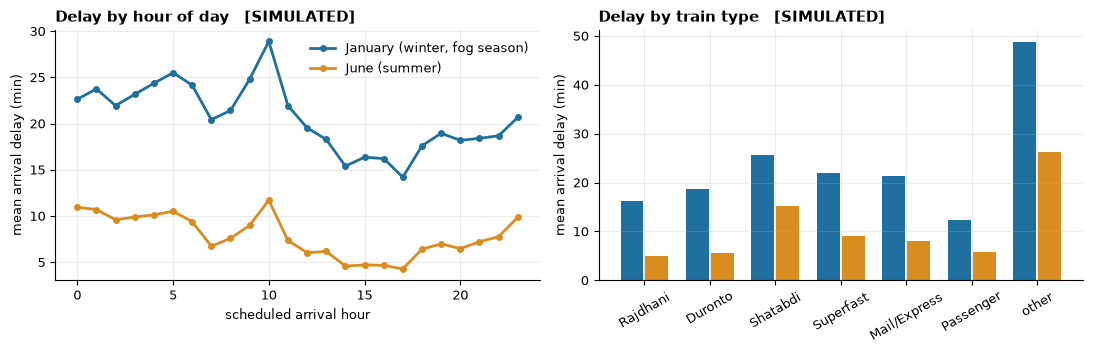

                   count       mean         p90  share<=10
run type                                                  
jan Duronto        25885  18.639999   56.610001       0.59
    Mail/Express  107105  21.389999   63.840000       0.58
    Passenger       4867  12.240000   31.790001       0.64
    Rajdhani       67704  16.160000   50.180000       0.62
    Shatabdi        7471  25.670000   79.959999       0.55
    Superfast     261950  21.900000   64.720001       0.56
    other           5053  48.790001  162.649994       0.45
jun Duronto        25050   5.680000   16.650000       0.84
    Mail/Express  103650   8.050000   26.700001       0.77
    Passenger       4710   5.860000   21.230000       0.71
    Rajdhani       65520   4.960000   20.020000       0.82
    Shatabdi        7230  15.180000   61.689999       0.68
    Superfast     253500   8.990000   26.139999       0.76
    other           4890  26.330000   76.570000       0.60


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for m in MONTHS:
    h = obs[obs.run == m].groupby("hour").arrival_delay.mean()
    axes[0].plot(h.index, h.values, color=COL[m], lw=2, marker="o", ms=4, label=MONTHS[m])
axes[0].set_xlabel("scheduled arrival hour"); axes[0].set_ylabel("mean arrival delay (min)"); axes[0].legend(frameon=False)
sim_title(axes[0], "Delay by hour of day")
order = ["Rajdhani", "Duronto", "Shatabdi", "Superfast", "Mail/Express", "Passenger", "other"]
w = 0.38
for k, m in enumerate(MONTHS):
    s = obs[obs.run == m].groupby("type").arrival_delay.mean().reindex(order)
    axes[1].bar(np.arange(len(order)) + (k - 0.5) * w, s.values, w * 0.92, color=COL[m], label=MONTHS[m])
axes[1].set_xticks(range(len(order))); axes[1].set_xticklabels(order, rotation=30); axes[1].set_ylabel("mean arrival delay (min)")
sim_title(axes[1], "Delay by train type"); plt.tight_layout(); plt.show()
print(obs.groupby(["run", "type"]).arrival_delay.agg(["count", "mean", lambda s: s.quantile(.9), lambda s: (s <= 10).mean()]).round(2).rename(columns={"<lambda_0>": "p90", "<lambda_1>": "share<=10"}))

In [6]:
tr = pd.read_parquet("data/processed/trains.parquet").set_index("number")
dist = obs.train.map(tr.full_route_distance_km)
bins = [0, 500, 1000, 1500, 5000]
obs["dist_bin"] = pd.cut(dist, bins, labels=["<500 km", "500-1000", "1000-1500", ">1500 km"])
print(obs.groupby(["run", "dist_bin"], observed=True).arrival_delay.agg(["count", "mean", lambda s: (s <= 10).mean()]).round(2)
      .rename(columns={"<lambda_0>": "share<=10"}))
print("\n(full-route distance comes from trains.json; 15 trains have none)")

                count       mean  share<=10
run dist_bin                               
jan <500 km     14105  16.950001       0.62
    500-1000    74245  21.400000       0.60
    1000-1500  184977  23.379999       0.54
    >1500 km   206708  19.110001       0.60
jun <500 km     13650   8.320000       0.75
    500-1000    71850   9.530000       0.77
    1000-1500  179010  10.030000       0.75
    >1500 km   200040   6.260000       0.80

(full-route distance comes from trains.json; 15 trains have none)


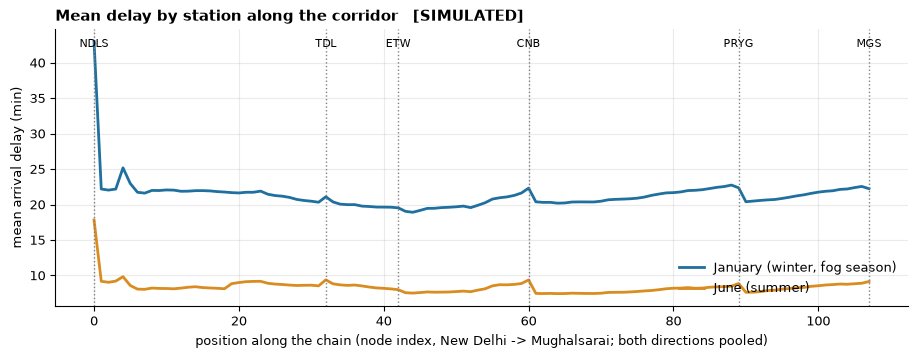

highest mean delay, January: {'NDLS': 43.0, 'ANVT': 25.200000762939453, 'ALD': 23.0, 'CNJ': 23.0, 'SFG': 22.700000762939453, 'COI': 22.600000381469727, 'JEP': 22.600000381469727, 'BMU': 22.5}
(delays pooled over both directions; the profile reflects where trains enter and which sections are busy)


In [7]:
# delay along the chain (node order), by month
node_of = {}
for sp in specs.values():
    for (stn, seq, k, j, n, *_rest) in sp.extra["rows"]:
        node_of[stn] = sp.visits[k].node
obs["node"] = obs.station.map(node_of)
fig, ax = plt.subplots(figsize=(11, 3.6))
for m in MONTHS:
    s = obs[obs.run == m].groupby("node").arrival_delay.mean()
    ax.plot(s.index, s.values, color=COL[m], lw=2, label=MONTHS[m])
for name in ["NDLS", "TDL", "ETW", "CNB", "PRYG", "MGS"]:
    i = net.node_names.index(name); ax.axvline(i, color="grey", ls=":", lw=1); ax.text(i, ax.get_ylim()[1] * 0.97, name, ha="center", va="top", fontsize=8)
ax.set_xlabel("position along the chain (node index, New Delhi -> Mughalsarai; both directions pooled)"); ax.set_ylabel("mean arrival delay (min)")
ax.legend(frameon=False, loc="lower right"); sim_title(ax, "Mean delay by station along the corridor"); plt.show()
top = obs[obs.run == "jan"].groupby("station").arrival_delay.mean().sort_values(ascending=False).head(8).round(1)
print("highest mean delay, January:", top.to_dict())
print("(delays pooled over both directions; the profile reflects where trains enter and which sections are busy)")

## 3. Typical delay along three trains' routes

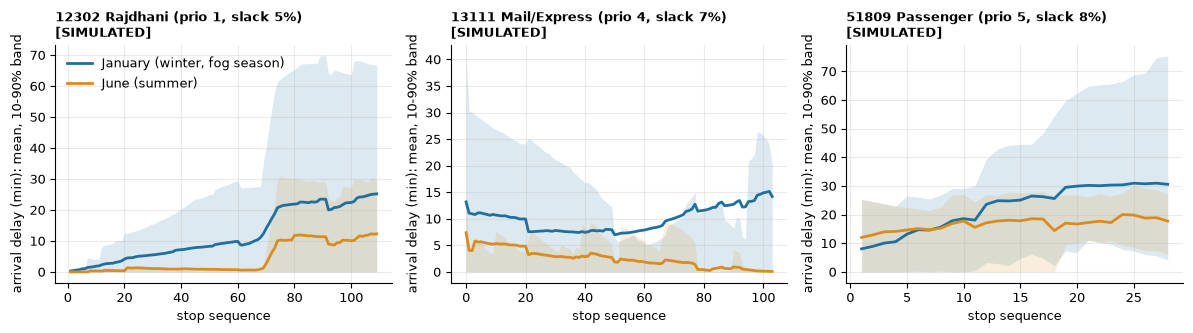

12302 Rajdhani: mean delay at first core stop 0.0 min, at last 18.8 min
13111 Mail/Express: mean delay at first core stop 10.3 min, at last 7.3 min
51809 Passenger: mean delay at first core stop 10.1 min, at last 24.3 min


In [8]:
pick = [("12302", "Rajdhani"), ("13111", "Mail/Express"), ("51809", "Passenger")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
for ax, (tn, lab) in zip(axes, pick):
    d = obs[obs.train == tn]
    for m in MONTHS:
        g = d[d.run == m].groupby("seq").arrival_delay
        mean, lo, hi = g.mean(), g.quantile(.1), g.quantile(.9)
        ax.plot(mean.index, mean.values, color=COL[m], lw=2, label=MONTHS[m])
        ax.fill_between(mean.index, lo.values, hi.values, color=COL[m], alpha=0.15, lw=0)
    sp = specs[tn]
    ax.set_title(f"{tn} {lab} (prio {sp.priority}, slack {sp.slack:.0%})\n[SIMULATED]", fontsize=9, loc="left", fontweight="bold")
    ax.set_xlabel("stop sequence"); ax.set_ylabel("arrival delay (min): mean, 10-90% band")
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
for tn, lab in pick:
    d = obs[obs.train == tn]
    f0 = d[d.seq == d.seq.min()]; first = f0.arrival_delay.fillna(f0.departure_delay).mean(); last = d[d.seq == d.seq.max()].arrival_delay.mean()
    print(f"{tn} {lab}: mean delay at first core stop {first:.1f} min, at last {last:.1f} min")

## 4. Queues on busy sections

A *queue* here is a set of trains waiting at the same station at the same time to enter the same section (held by headway, a yield, freight or a disruption). The simulator logs each such wait with its start and end.

In [9]:
def max_queue(g):
    ev = np.r_[g.wait_start.values, g.wait_end.values]
    w = np.r_[np.ones(len(g)), -np.ones(len(g))]
    o = np.lexsort((w, ev))               # at equal time, departures (-1) before arrivals (+1)
    return int(np.cumsum(w[o]).max())
q = queues[queues.wait_end - queues.wait_start > 0.5]
rows = []
for (m, sec, d), g in q.groupby(["run", "section", "direction"]):
    rows.append((m, sec, d, len(g), (g.wait_end - g.wait_start).sum(), max_queue(g)))
qs = pd.DataFrame(rows, columns=["run", "section", "direction", "waits", "wait_minutes", "max_queue"])
passages = {}
for sp in specs.values():
    for h in sp.hops:
        if h.kind == "section":
            for s in h.sections:
                passages[(s, h.direction)] = passages.get((s, h.direction), 0) + 1
qs["trains_per_day"] = [passages.get((s, d), 0) for s, d in zip(qs.section, qs.direction)]
qs["name"] = [f"{net.node_names[s]}-{net.node_names[s + 1]}" for s in qs.section]
print("sections/directions with a queue of 3+ trains at once:", qs[qs.max_queue >= 3].groupby("run").size().to_dict(),
      "| of", len(passages), "section-directions")
print("largest simultaneous queue:", qs.groupby("run").max_queue.max().to_dict())
print(qs.sort_values("max_queue", ascending=False).head(10)[["run", "name", "direction", "trains_per_day", "waits", "wait_minutes", "max_queue"]].round(0).to_string(index=False))

sections/directions with a queue of 3+ trains at once: {'jan': 202, 'jun': 193} | of 214 section-directions
largest simultaneous queue: {'jan': 12, 'jun': 15}
run     name  direction  trains_per_day  waits  wait_minutes  max_queue
jun  DAR-SOM          1              64     87         982.0         15
jan  MNR-SKB         -1              90    653        2421.0         12
jun ANVT-CNJ         -1              50    142        1440.0         11
jan SHW-GHSR          1              92    410        2026.0         10
jun AJR-DKDE          1              63     46        1159.0         10
jun  SKB-KAA          1              92    300        1424.0          9
jan GHSR-ULD          1              92    316        1119.0          9
jan SFG-PRYG          1              70    338         895.0          8
jan  BDN-BBL         -1              89    528        1422.0          8
jan HRS-PORA         -1              63    283         976.0          8


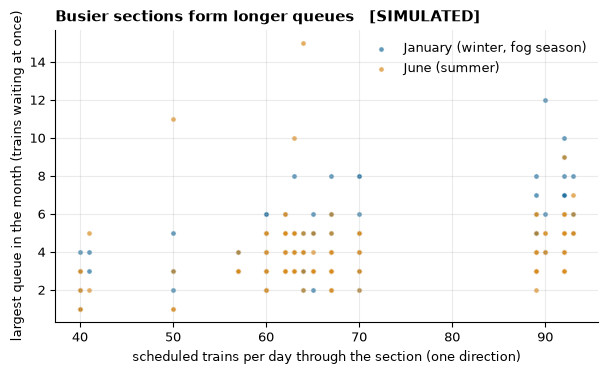

correlation of traffic and largest queue: {'jan': 0.45, 'jun': 0.22}


In [10]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for m in MONTHS:
    s = qs[qs.run == m]
    ax.scatter(s.trains_per_day, s.max_queue, s=14, color=COL[m], alpha=0.7, label=MONTHS[m], edgecolor="white", linewidth=0.5)
ax.set_xlabel("scheduled trains per day through the section (one direction)"); ax.set_ylabel("largest queue in the month (trains waiting at once)")
ax.legend(frameon=False); sim_title(ax, "Busier sections form longer queues"); plt.show()
c = qs.groupby("run").apply(lambda s: np.corrcoef(s.trains_per_day, s.max_queue)[0, 1], include_groups=False).round(2)
print("correlation of traffic and largest queue:", c.to_dict())

## 5. One cascade traced through the ground-truth labels

In [11]:
ev = events.rename(columns={"event_id": "root_event_id"})
a = attr[(attr.phase == "arr") & (attr.new_minutes >= 1)].merge(
    obs[["run", "obs_id", "train", "date", "station", "seq", "actual_arrival", "arrival_delay"]], on=["run", "obs_id"], suffixes=("_cause", ""))
a["cause_train"] = a.cause_train.astype(str).replace("nan", "")
others = a[a.cause_code.isin([C.SECTION_WAIT, C.YIELD, C.RAKE]) & (a.root_event_id > 0)]
spread = others.groupby(["run", "root_event_id"]).apply(lambda g: g[["train", "date"]].drop_duplicates().shape[0], include_groups=False)
spread = spread.rename("runs_delayed").reset_index().merge(ev[["run", "root_event_id", "type", "train", "place", "duration_min", "date"]], on=["run", "root_event_id"])
spread = spread[spread.type.isin(["section_incident", "disruption_block", "disruption_signal"])]
print(spread.sort_values("runs_delayed", ascending=False).head(5).to_string(index=False))
E = spread.sort_values("runs_delayed", ascending=False).iloc[0]
print("\nchosen event:", E.to_dict())

run  root_event_id  runs_delayed             type train    place  duration_min       date
jan           1639            45 section_incident 14006  GZB-MIU     33.784435 2025-01-02
jun           6018            34 section_incident 03686 KAMP-DAR    235.248901 2025-06-20
jan           7181            27 section_incident 12440 NDLS-CSB     32.917744 2025-01-21
jan           8978            25 section_incident 13040 KRJ-KAMP     32.417622 2025-01-27
jan           7968            24 section_incident 12402  BNT-SHW     58.516876 2025-01-24

chosen event: {'run': 'jan', 'root_event_id': 1639, 'runs_delayed': 45, 'type': 'section_incident', 'train': '14006', 'place': 'GZB-MIU', 'duration_min': 33.7844352722168, 'date': Timestamp('2025-01-02 00:00:00')}


In [12]:
mask = (a.run == E.run) & (a.root_event_id == E.root_event_id) & a.cause_code.isin([C.INCIDENT, C.DISRUPTION, C.SECTION_WAIT, C.YIELD, C.RAKE])
t = a[mask].copy()
t["time"] = pd.to_datetime(t.date) + pd.to_timedelta(t.actual_arrival, unit="m")
t["cause"] = t.cause_code.map(C.NAMES)
# depth: 0 = the train hit directly by the event; each "caused by" link adds one hop
depth = {}
direct = t[t.cause_code.isin([C.INCIDENT, C.DISRUPTION])].train.unique()
for x in direct: depth[x] = 0
changed = True
while changed:
    changed = False
    for _, r in t.sort_values("time").iterrows():
        if r.cause_code in (C.SECTION_WAIT, C.YIELD, C.RAKE) and r.cause_train in depth and r.train not in depth:
            depth[r.train] = depth[r.cause_train] + 1; changed = True
t["hops_from_event"] = t.train.map(depth)
first = t.sort_values("time").groupby("train").head(1).sort_values("time")
print(f"Event {int(E.root_event_id)} ({E.type}) on {pd.Timestamp(E.date).date()} at {E.place}, duration {E.duration_min:.0f} min, train {E.train or '-'}")
print("trains delayed through it:", t.train.nunique(), "| max hops from the event:", int(t.hops_from_event.max()))
print(first[["time", "train", "station", "cause", "cause_train", "new_minutes", "hops_from_event", "arrival_delay"]].head(18).round({"new_minutes": 1, "arrival_delay": 1}).to_string(index=False))

Event 1639 (section_incident) on 2025-01-02 at GZB-MIU, duration 34 min, train 14006
trains delayed through it: 45 | max hops from the event: 8
                         time train station        cause cause_train  new_minutes  hops_from_event  arrival_delay
2025-01-02 16:55:28.634033202 14006     MIU     incident         NaN    33.799999                0      33.799999
2025-01-02 16:56:28.634033202 12440     MIU section_wait       14006    25.000000                1      25.000000
2025-01-02 16:56:28.634033202 12878     MIU section_wait       12454    25.000000                4      25.000000
2025-01-02 16:56:28.634033202 12454     MIU section_wait       12440    25.000000                2      25.000000
2025-01-02 16:57:28.634033202 12034     MIU section_wait       12878    18.700001                3      18.700001
2025-01-02 16:57:49.288330080 13040     MIU section_wait       12034    12.900000                3      18.700001
2025-01-02 16:58:49.288330080 12314     MIU section_wait  

In [13]:
# the chain, in words, and a check that the labels add up for one follower
chain = first.sort_values("time")
steps = [f"{r.cause_train or 'event'} -> {r.train} ({r.cause}, {r.new_minutes:.0f} min at {r.station})" for r in chain.head(8).itertuples()]
print("\n".join(steps))
x = chain[chain.cause_code != C.INCIDENT].iloc[0]
full = attr[(attr.run == x.run) & (attr.obs_id == x.obs_id) & (attr.phase == "arr")]
print(f"\nAll labelled minutes for {x.train} at {x.station}: observed arrival delay {x.arrival_delay:.1f} min, "
      f"components sum {full[full.cause_code > 0].minutes.sum():.1f}")
print(full[["cause_code", "minutes", "new_minutes", "cause_train", "event_id", "root_event_id"]].assign(cause=lambda d: d.cause_code.map(C.NAMES)).round(1).to_string(index=False))

nan -> 14006 (incident, 34 min at MIU)
14006 -> 12440 (section_wait, 25 min at MIU)
12454 -> 12878 (section_wait, 25 min at MIU)
12440 -> 12454 (section_wait, 25 min at MIU)
12878 -> 12034 (section_wait, 19 min at MIU)
12034 -> 13040 (section_wait, 13 min at MIU)
13040 -> 12314 (section_wait, 7 min at MIU)
12314 -> 12304 (section_wait, 4 min at DER)

All labelled minutes for 12440 at MIU: observed arrival delay 25.0 min, components sum 25.0
 cause_code  minutes  new_minutes cause_train  event_id  root_event_id        cause
          4     25.0         25.0       14006         0           1639 section_wait


## 6. Share of delay by cause

share of delay minutes ADDED (each minute counted once, when it is added):
 run               jan    jun
cause_code                  
incident        0.054  0.066
disruption      0.002  0.016
weather         0.227  0.017
section_wait    0.417  0.530
yield           0.111  0.162
freight         0.018  0.033
rake_reuse      0.003  0.001
halt_extension  0.010  0.016
entry_delay     0.158  0.160

caused by other trains (section wait + yield + rake reuse): {'jan': 0.531000018119812, 'jun': 0.6930000185966492}


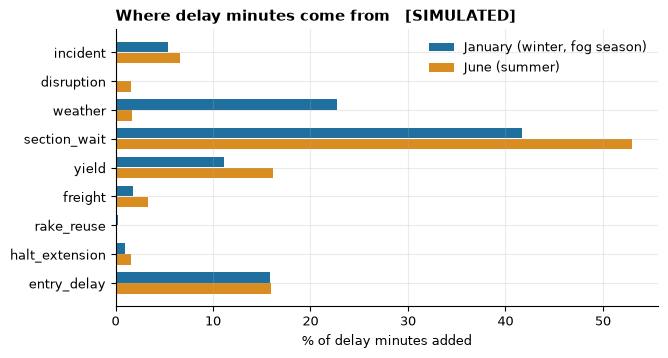

In [14]:
arr = attr[attr.phase == "arr"]
def share(col):
    s = arr[arr.cause_code > 0].groupby(["run", "cause_code"])[col].sum().unstack(0).fillna(0)
    s = s / s.sum()
    s.index = s.index.map(C.NAMES)
    return s.round(3)
added, felt = share("new_minutes"), share("minutes")
print("share of delay minutes ADDED (each minute counted once, when it is added):\n", added)
others = [C.NAMES[c] for c in (C.SECTION_WAIT, C.YIELD, C.RAKE)]
print("\ncaused by other trains (section wait + yield + rake reuse):", added.loc[others].sum().round(3).to_dict())
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(added));
for k, m in enumerate(MONTHS):
    ax.barh(y + (k - 0.5) * 0.38, added[m].values * 100, 0.36, color=COL[m], label=MONTHS[m])
ax.set_yticks(y); ax.set_yticklabels(added.index); ax.invert_yaxis(); ax.set_xlabel("% of delay minutes added")
ax.legend(frameon=False); sim_title(ax, "Where delay minutes come from"); plt.show()

## 6b. Priority sanity check (clear weather)

Expected if priority works: mean delay ordered Rajdhani / Shatabdi / Duronto <= Superfast <= Mail/Express <= Passenger. Raw mean delay is also shaped by how long a train stays in the corridor and whether it enters mid-route (Passenger trains are short and mostly start inside the corridor), so a second measure removes that exposure: **delay minutes added by other trains (waits, yields, rake) per 100 logged rows**.

In [15]:
clear = o[(o.state == "clear")].copy()
order = ["Rajdhani", "Duronto", "Shatabdi", "Superfast", "Mail/Express", "Passenger"]
raw = clear.groupby("type").arrival_delay.agg(["count", "mean", lambda s: (s <= 10).mean()]).reindex(order)
raw.columns = ["rows", "mean delay (clear)", "share <=10 min"]
clear_ids = clear[["run", "obs_id", "type"]]
ad = attr[(attr.phase == "arr") & attr.cause_code.isin([C.SECTION_WAIT, C.YIELD, C.RAKE])].merge(clear_ids, on=["run", "obs_id"])
raw["added by others / 100 rows"] = ad.groupby("type").new_minutes.sum().reindex(order) / raw.rows * 100
first = clear.sort_values("seq").groupby(["run", "train", "date"]).head(1)
raw["mean delay at first row"] = first.groupby("type").arrival_delay.mean().reindex(order)
raw["trains"] = [sum(1 for s in specs.values() if s.type == t_) for t_ in order]
raw["share entering mid-route"] = [np.mean([s.entered_mid_route for s in specs.values() if s.type == t_]) for t_ in order]
raw["mean rows per run"] = [np.mean([len(s.extra["rows"]) for s in specs.values() if s.type == t_]) for t_ in order]
print(raw.round(2).to_string())
m = raw["mean delay (clear)"]
chk = {"Rajdhani <= Superfast": m.Rajdhani <= m.Superfast, "Duronto <= Superfast": m.Duronto <= m.Superfast, "Shatabdi <= Superfast": m.Shatabdi <= m.Superfast,
       "Superfast <= Mail/Express": m.Superfast <= m["Mail/Express"], "Mail/Express <= Passenger": m["Mail/Express"] <= m.Passenger}
print("\nORDER CHECK on raw mean delay:", "PASS" if all(chk.values()) else "FAIL", chk)
a_ = raw["added by others / 100 rows"]
chk2 = {"Rajdhani <= Superfast": a_.Rajdhani <= a_.Superfast, "Duronto <= Superfast": a_.Duronto <= a_.Superfast, "Shatabdi <= Superfast": a_.Shatabdi <= a_.Superfast,
        "Superfast <= Mail/Express": a_.Superfast <= a_["Mail/Express"], "Mail/Express <= Passenger": a_["Mail/Express"] <= a_.Passenger}
print("ORDER CHECK on delay added by other trains per 100 rows:", "PASS" if all(chk2.values()) else "FAIL", chk2)

                rows  mean delay (clear)  share <=10 min  added by others / 100 rows  mean delay at first row  trains  share entering mid-route  mean rows per run
type                                                                                                                                                              
Rajdhani      107016                6.45            0.80                       18.81                     4.74      20                      0.50             109.70
Duronto        40915                7.05            0.80                       19.20                     4.97       8                      0.38             105.00
Shatabdi       11809               15.25            0.68                       49.89                     2.75       4                      0.25              61.00
Superfast     414050               10.26            0.74                       28.77                     7.63     107                      0.68              79.29
Mail/Express  169295  

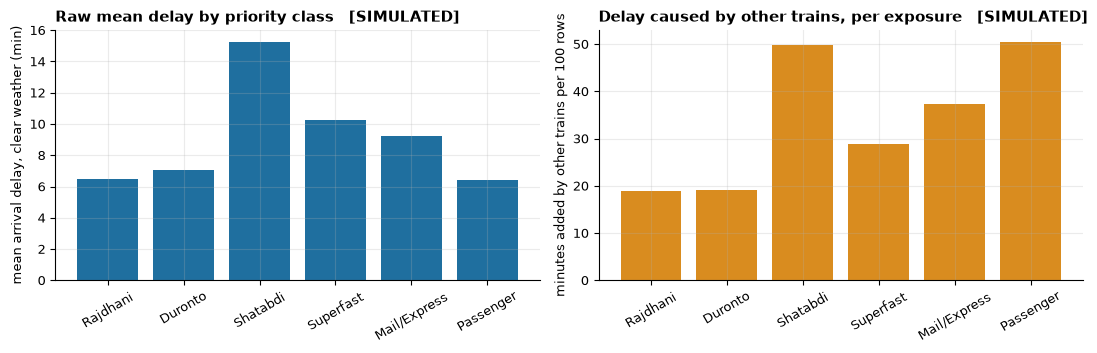

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(order))
axes[0].bar(x, raw["mean delay (clear)"], color="#1f6f9f"); axes[0].set_ylabel("mean arrival delay, clear weather (min)")
sim_title(axes[0], "Raw mean delay by priority class")
axes[1].bar(x, raw["added by others / 100 rows"], color="#d98c1f"); axes[1].set_ylabel("minutes added by other trains per 100 rows")
sim_title(axes[1], "Delay caused by other trains, per exposure")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(order, rotation=30)
plt.tight_layout(); plt.show()

In [17]:
# why is Shatabdi high? Four trains only; which trains delay them, where
sh = o[(o.state == "clear") & (o.type == "Shatabdi")]
print(sh.groupby("train").arrival_delay.agg(["count", "mean"]).round(1).T.to_string())
ash = attr[(attr.phase == "arr") & (attr.new_minutes > 0.5) & attr.cause_code.isin([C.SECTION_WAIT, C.YIELD])].merge(
    sh[["run", "obs_id", "station"]], on=["run", "obs_id"])
print("who delays the Shatabdi trains (minutes):", ash.groupby("cause_train", observed=True).new_minutes.sum().sort_values(ascending=False).head(5).round(0).to_dict())
print("where:", ash.groupby("station").new_minutes.sum().sort_values(ascending=False).head(5).round(0).to_dict())

train   12003   12004   12033   12034
count  2989.0  2940.0  2940.0  2940.0
mean     28.4     1.6    27.6     3.2
who delays the Shatabdi trains (minutes): {'18631': 1310.0, '51809': 884.0, '12379': 561.0, '12453': 437.0, '12439': 413.0}
where: {'ETW': 1011.0, 'SKB': 542.0, 'TDL': 350.0, 'FZD': 265.0, 'HNG': 245.0}


## 7. Sensitivity: headway and slack

Each variant simulates the same two months with one parameter changed: headway 3 / 4 (default) / 6 minutes, slack scaled to about 3% / 6% / 10% on average (x0.5 / x1 / x1.67 of the per-type defaults), and the earlier overtaking rule (junction or real halt only, no penalty) for comparison. Same seed throughout.

In [18]:
base_slack = load_config()["movement"]["slack"]
variants = {"headway 3": {"movement": {"headway_min": 3}}, "headway 4 (default)": {}, "headway 6": {"movement": {"headway_min": 6}},
            "old overtaking rule": {"movement": {"overtake_mode": "junction_or_halt"}},
            "slack ~3%": {"movement": {"slack": {k: v * 0.5 for k, v in base_slack.items()}}},
            "slack ~10%": {"movement": {"slack": {k: v * 5 / 3 for k, v in base_slack.items()}}}}
rows = []
for name, ov in variants.items():
    c = load_config(overrides=ov)
    built = load_specs(cfg=c)
    for m, (a0, b0) in {"jan": ("2025-01-01", "2025-01-31"), "jun": ("2025-06-01", "2025-06-30")}.items():
        r = simulate(to_day(a0), to_day(b0), c, built=built)
        rec = r["recorder"]; df, da = rec.tables(rec.months()[0])
        d = df.arrival_delay.dropna()
        new = da[(da.phase == "arr") & (da.cause_code > 0)].groupby("cause_code").new_minutes.sum()
        rows.append({"variant": name, "month": m, "mean delay": d.mean(), "p90": d.quantile(.9), "share <=10 min": (d <= 10).mean(),
                     "caused by other trains": new.reindex([4, 5, 7]).fillna(0).sum() / new.sum()})
sens = pd.DataFrame(rows).round(3)
print(sens.pivot(index="variant", columns="month").round(2).to_string())

                    mean delay           p90        share <=10 min       caused by other trains      
month                      jan    jun    jan    jun            jan   jun                    jan   jun
variant                                                                                              
headway 3            18.799999   6.82  56.98  20.97           0.61  0.81                   0.48  0.64
headway 4 (default)  21.049999   8.28  63.08  25.21           0.58  0.78                   0.53  0.69
headway 6            30.100000  14.98  88.01  43.02           0.50  0.68                   0.65  0.80
old overtaking rule  23.290001   9.80  70.10  31.34           0.56  0.76                   0.56  0.73
slack ~10%           15.370000   5.94  48.73  17.73           0.67  0.85                   0.49  0.64
slack ~3%            27.040001  12.27  76.79  34.42           0.49  0.68                   0.57  0.74


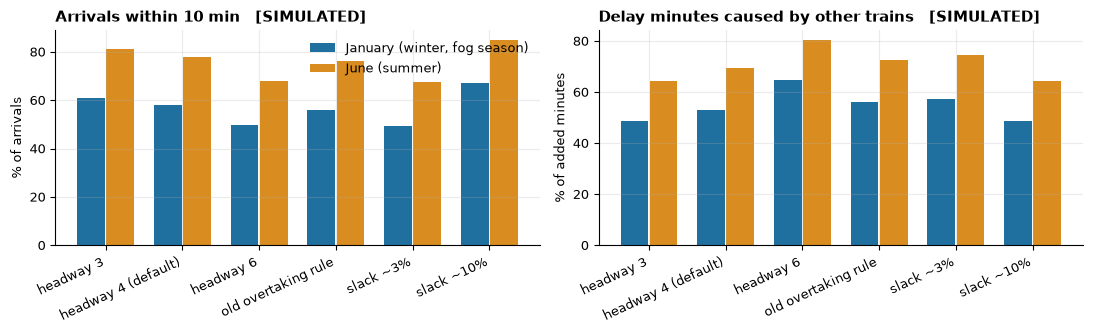

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
order = list(variants)
for k, m in enumerate(["jan", "jun"]):
    s = sens[sens.month == m].set_index("variant").reindex(order)
    axes[0].bar(np.arange(len(order)) + (k - 0.5) * 0.38, s["share <=10 min"] * 100, 0.36, color=COL[m], label=MONTHS[m])
    axes[1].bar(np.arange(len(order)) + (k - 0.5) * 0.38, s["caused by other trains"] * 100, 0.36, color=COL[m])
for ax, t, yl in zip(axes, ["Arrivals within 10 min", "Delay minutes caused by other trains"], ["% of arrivals", "% of added minutes"]):
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha="right"); ax.set_ylabel(yl); sim_title(ax, t)
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

## 8. Runtime and size

In [20]:
t = pd.DataFrame(timing).T
t["MB on disk"] = (t.bytes.astype(float) / 1e6).round(1)
print(t[["runs", "observation_rows", "simulate_seconds", "write_seconds", "MB on disk", "ledger_max_mismatch"]])
mean_s, mean_mb = t.total_seconds.astype(float).mean(), t["MB on disk"].mean()
print(f"\nextrapolated to 12 months: about {12 * mean_s / 60:.1f} minutes and {12 * mean_mb:.0f} MB (every core station logged)")

       runs  observation_rows  simulate_seconds  write_seconds  MB on disk  ledger_max_mismatch
jan  6975.0          482050.0              38.4            2.8        23.8         8.996892e-11
jun  6750.0          466500.0              35.9            2.0        16.3         3.827756e-10

extrapolated to 12 months: about 8.0 minutes and 241 MB (every core station logged)


## What this does and does not show

* The simulator runs, the cause ledger adds up (maximum mismatch is the number printed in the runtime section), and a cascade can be followed from one event through other trains' delays.
* Parameters were **not** tuned to reach the 70-85% on-time or 15-35% other-train-delay targets. The numbers above are where the model lands; compare them with the targets in section 1 and the sensitivity table.
* The world is cascade-heavy: most added delay minutes are caused by other trains (see section 6), and queues of ten or more trains form on busy sections.
* These numbers are the output of assumed parameters. They say nothing about how Indian Railways actually performs.